In [1]:
# 05 - Model Explainability (SHAP + Permutation Importance)
# Explains the two production models: Random Forest (cost) and XGBoost (CO2).
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parents[1])
print("Working directory:", Path.cwd())

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

OUT = Path("outputs/explainability")
OUT.mkdir(parents=True, exist_ok=True)
print("shap", shap.__version__, "| matplotlib", matplotlib.__version__)

Working directory: C:\Users\shame\OneDrive\Desktop\EcoPackAI


shap 0.46.0 | matplotlib 3.11.2


C:\Users\shame\anaconda3\envs\ecopackai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
materials = pd.read_csv("data/processed/materials.csv")
train_df, test_df = train_test_split(materials, test_size=0.2, random_state=42)

MODELS = {
    "cost": {"file": "ml/models/rf_cost.joblib", "target": "cost_per_unit_usd",
             "title": "Random Forest - cost per unit (USD)"},
    "co2": {"file": "ml/models/xgb_co2.joblib", "target": "co2_emission_per_kg",
            "title": "XGBoost - CO2 per kg"},
}
for key, info in MODELS.items():
    info["pipeline"] = joblib.load(info["file"])

preprocessor = MODELS["cost"]["pipeline"].named_steps["preprocess"]
numeric_cols, nominal_cols, ordinal_cols = [cols for _, _, cols in preprocessor.transformers_[:3]]
raw_features = numeric_cols + nominal_cols + ordinal_cols
feature_names = preprocessor.get_feature_names_out()
X_test = preprocessor.transform(test_df)

print("Raw input features:", len(raw_features), "| Model features after encoding:", len(feature_names))
print("Explaining", len(test_df), "unseen test materials")

Raw input features: 18 | Model features after encoding: 31
Explaining 81 unseen test materials


In [3]:
def readable(name):
    """num__reusability_percent -> reusability_percent; nom__material_type_Steel -> material_type = Steel"""
    kind, feature = name.split("__", 1)
    if kind == "nom":
        for col in nominal_cols:
            if feature.startswith(col + "_"):
                return f"{col} = {feature[len(col) + 1:]}"
    return feature


def original_feature(name):
    """Map every encoded column back to the raw column it came from."""
    kind, feature = name.split("__", 1)
    if kind == "nom":
        return next(col for col in nominal_cols if feature.startswith(col + "_"))
    return feature


def display_values(rows):
    """Real-world values (not scaled) for each encoded column, for readable local plots."""
    values = {}
    for name in feature_names:
        kind, feature = name.split("__", 1)
        if kind == "nom":
            col = original_feature(name)
            values[name] = (rows[col] == feature[len(col) + 1:]).astype(int).to_numpy()
        else:
            values[name] = rows[feature].to_numpy()
    return pd.DataFrame(values)


labels = [readable(n) for n in feature_names]
print(labels[:3], "...", labels[-3:])

['recyclability_percent', 'recycled_content_percent', 'reusability_percent'] ... ['supplier_region = LATAM', 'supplier_region = ROW', 'recyclability_category']


In [4]:
for key, info in MODELS.items():
    explainer = shap.TreeExplainer(info["pipeline"].named_steps["model"])
    explanation = explainer(X_test)
    explanation.feature_names = labels
    info["shap"] = explanation

    # Sanity check: base value + contributions must equal the model's prediction
    rebuilt = explanation.values.sum(axis=1) + explanation.base_values
    gap = np.abs(rebuilt - info["pipeline"].predict(test_df)).max()
    print(f"{key}: base value {explanation.base_values[0]:.3f}, "
          f"max gap between SHAP sum and prediction = {gap:.1e}")

cost: base value 8.987, max gap between SHAP sum and prediction = 9.9e-14
co2: base value 1.169, max gap between SHAP sum and prediction = 9.5e-07


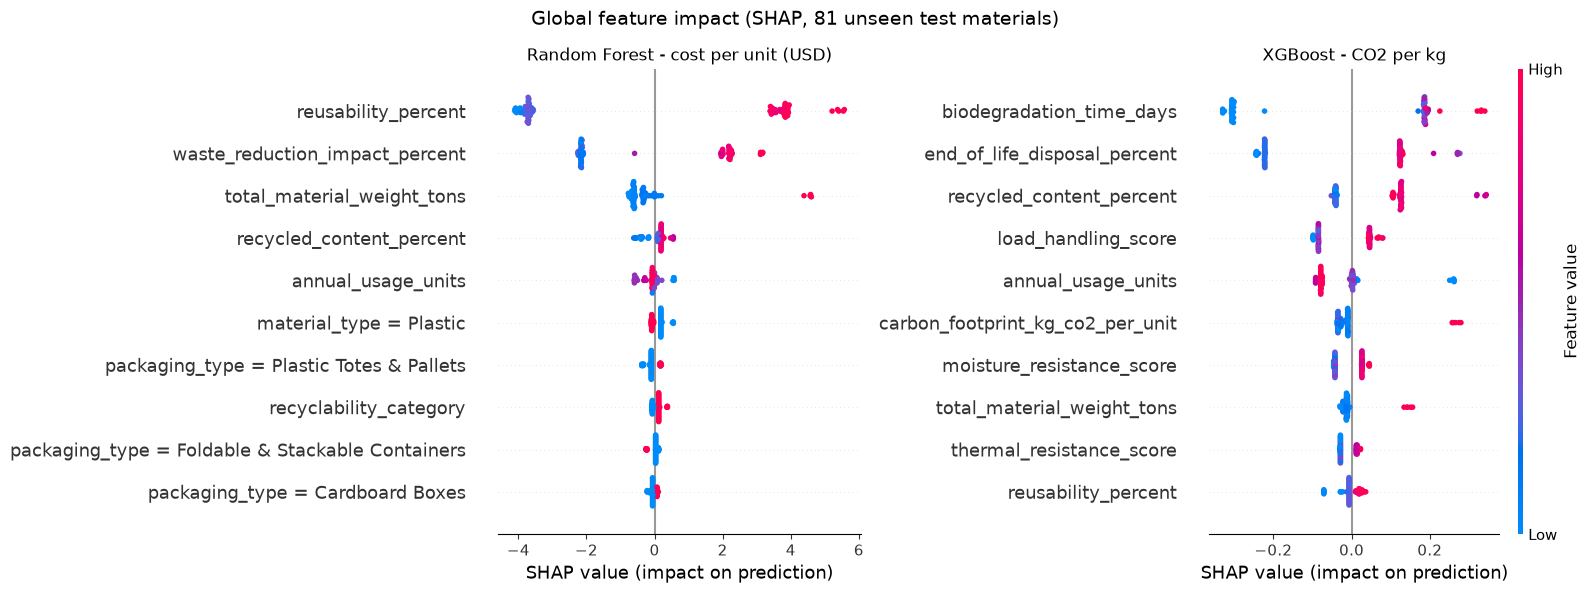

In [5]:
fig = plt.figure(figsize=(16, 6))
for i, (key, info) in enumerate(MODELS.items(), start=1):
    plt.subplot(1, 2, i)
    np.random.seed(42)   # SHAP places the dots with random jitter; fix it so the image is reproducible
    shap.summary_plot(info["shap"].values, X_test, feature_names=labels, max_display=10,
                      show=False, plot_size=None, color_bar=(i == 2))
    plt.title(info["title"], fontsize=12)
    plt.xlabel("SHAP value (impact on prediction)")
plt.suptitle("Global feature impact (SHAP, 81 unseen test materials)", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
shap_rows = []
for key, info in MODELS.items():
    per_raw_feature = (
        pd.DataFrame(info["shap"].values, columns=[original_feature(n) for n in feature_names])
        .T.groupby(level=0).sum().T          # add up the one-hot columns of each raw feature
        .abs().mean()
        .sort_values(ascending=False)
    )
    for rank, (feature, value) in enumerate(per_raw_feature.items(), start=1):
        shap_rows.append({"model": key, "feature": feature, "mean_abs_shap": value, "rank": rank})

shap_importance = pd.DataFrame(shap_rows)
shap_importance.round(6).to_csv(OUT / "shap_importance.csv", index=False)
shap_importance.pivot(index="rank", columns="model", values="feature").head(8)

model,co2,cost
rank,,
1,biodegradation_time_days,reusability_percent
2,end_of_life_disposal_percent,waste_reduction_impact_percent
3,recycled_content_percent,total_material_weight_tons
4,load_handling_score,recycled_content_percent
5,annual_usage_units,material_type
6,carbon_footprint_kg_co2_per_unit,packaging_type
7,moisture_resistance_score,annual_usage_units
8,total_material_weight_tons,recyclability_category


In [7]:
perm_rows = []
for key, info in MODELS.items():
    result = permutation_importance(
        info["pipeline"], test_df[raw_features], test_df[info["target"]],
        n_repeats=30, random_state=42, scoring="neg_root_mean_squared_error", n_jobs=-1,
    )
    for feature, mean, std in zip(raw_features, result.importances_mean, result.importances_std):
        perm_rows.append({"model": key, "feature": feature, "rmse_increase": mean, "std": std})

perm = pd.DataFrame(perm_rows).sort_values(["model", "rmse_increase"], ascending=[True, False])
perm["rank"] = perm.groupby("model").cumcount() + 1
# rounded: Random Forest threads change only the ~15th digit between runs
perm.round(6).to_csv(OUT / "permutation_importance.csv", index=False)
perm.pivot(index="rank", columns="model", values="feature").head(8)

model,co2,cost
rank,,
1,biodegradation_time_days,reusability_percent
2,end_of_life_disposal_percent,waste_reduction_impact_percent
3,recycled_content_percent,total_material_weight_tons
4,annual_usage_units,recycled_content_percent
5,carbon_footprint_kg_co2_per_unit,annual_usage_units
6,load_handling_score,material_type
7,total_material_weight_tons,packaging_type
8,reusability_percent,recyclability_category


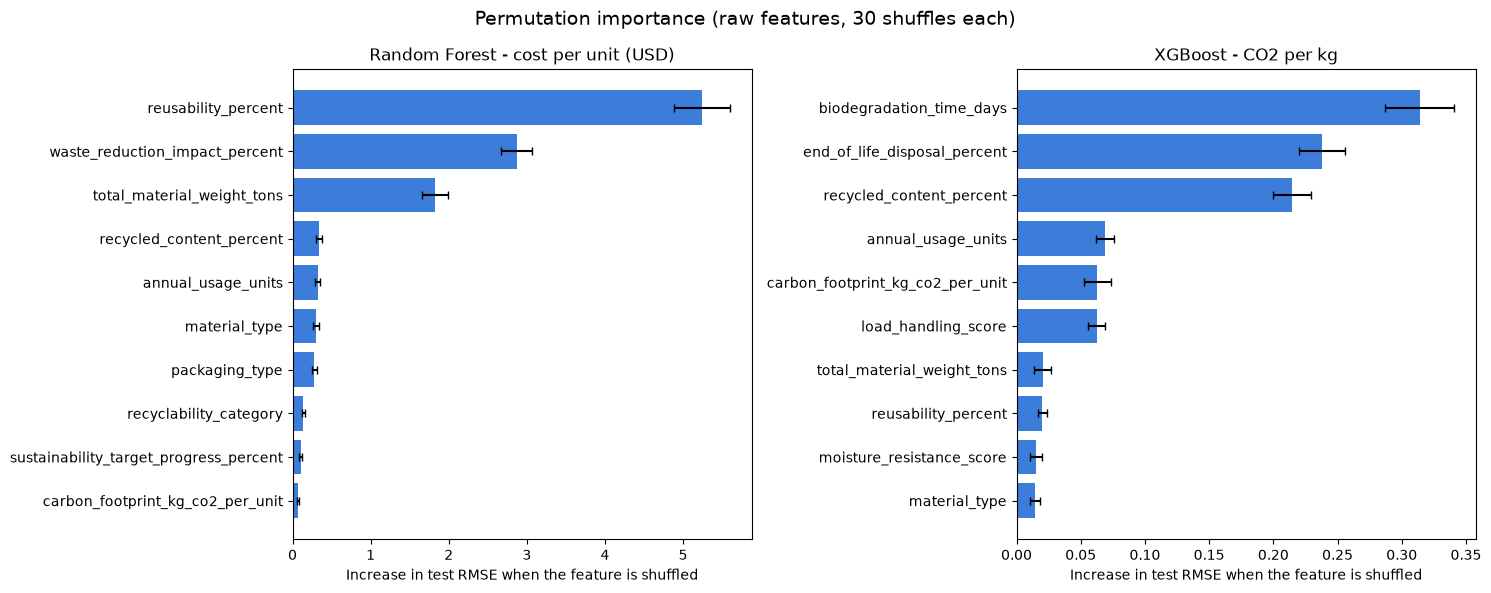

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (key, info) in zip(axes, MODELS.items()):
    top = perm[perm["model"] == key].head(10).iloc[::-1]
    ax.barh(top["feature"], top["rmse_increase"], xerr=top["std"], color="#3b7dd8", capsize=3)
    ax.set_title(info["title"], fontsize=12)
    ax.set_xlabel("Increase in test RMSE when the feature is shuffled")
fig.suptitle("Permutation importance (raw features, 30 shuffles each)", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

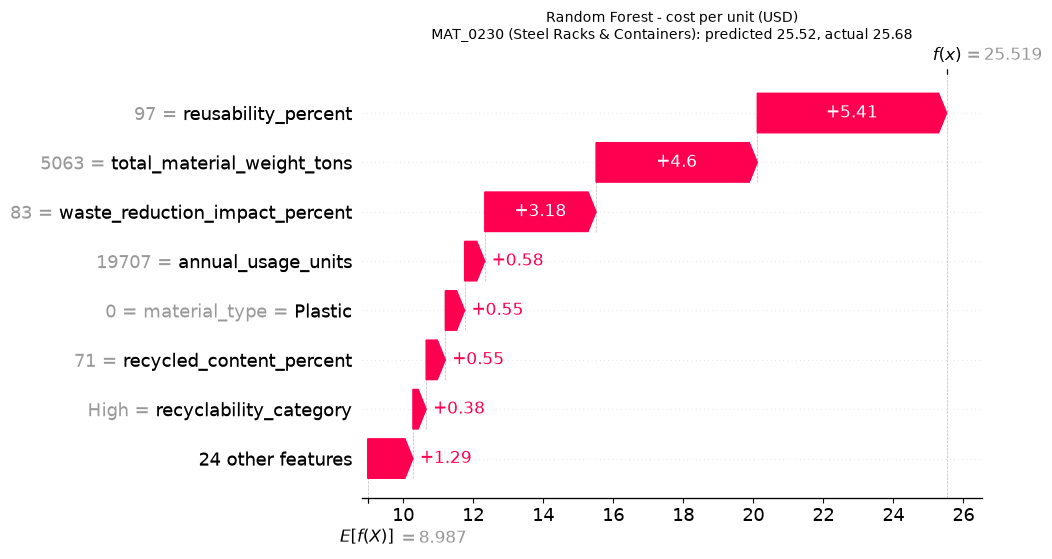

cost high: MAT_0230 Steel Racks & Containers predicted 25.519 actual 25.680


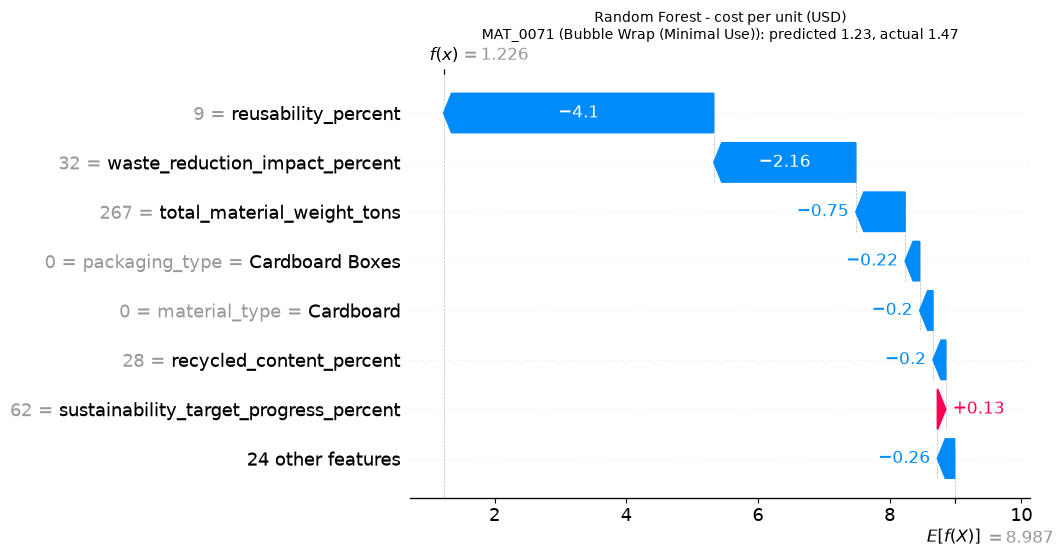

cost low: MAT_0071 Bubble Wrap (Minimal Use) predicted 1.226 actual 1.470


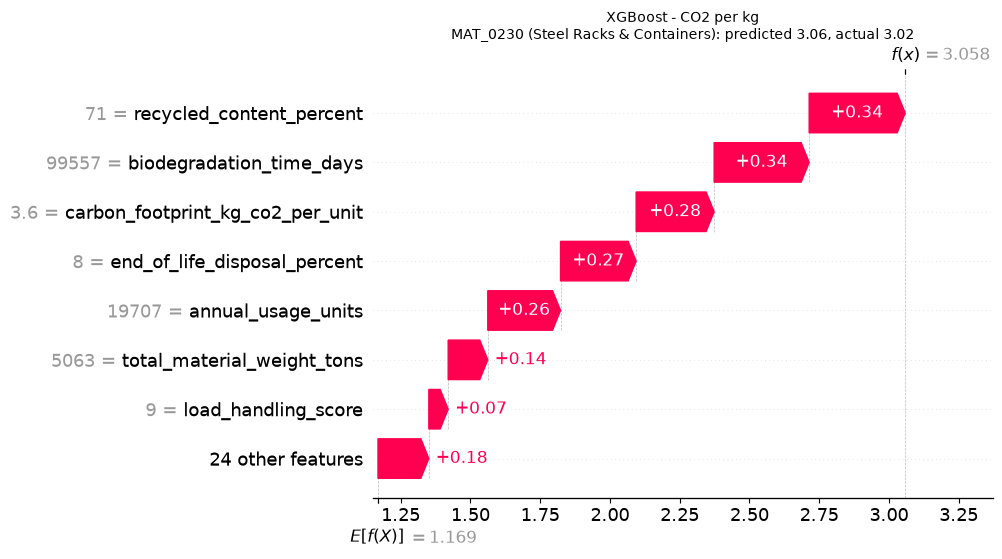

co2 high: MAT_0230 Steel Racks & Containers predicted 3.058 actual 3.020


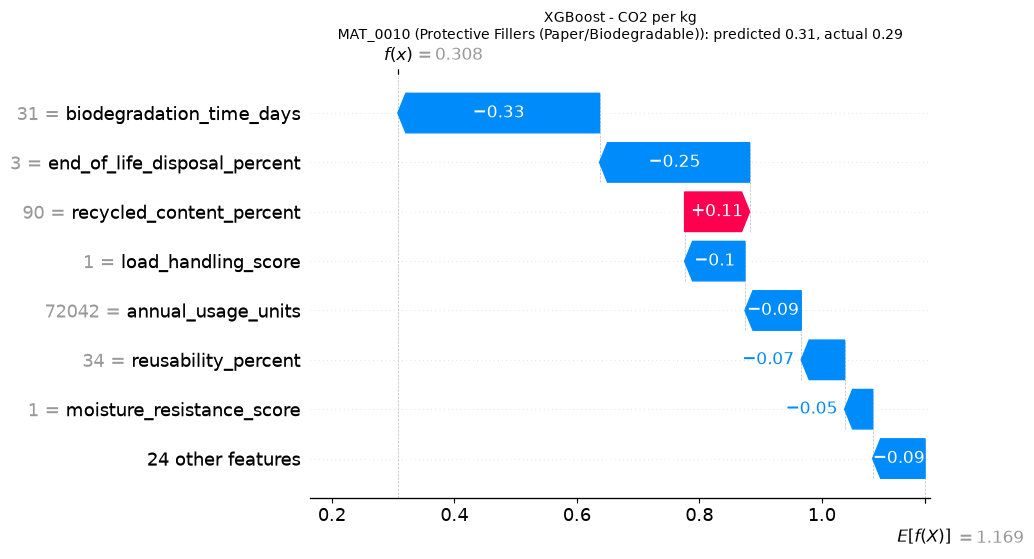

co2 low: MAT_0010 Protective Fillers (Paper/Biodegradable) predicted 0.308 actual 0.290


In [9]:
shown = test_df.reset_index(drop=True)
real_values = display_values(shown)

for key, info in MODELS.items():
    predictions = info["pipeline"].predict(test_df)
    for which, position in [("high", int(np.argmax(predictions))), ("low", int(np.argmin(predictions)))]:
        row = shown.iloc[position]
        single = shap.Explanation(
            values=info["shap"].values[position],
            base_values=info["shap"].base_values[position],
            data=real_values.iloc[position].to_numpy(),
            feature_names=labels,
        )
        plt.figure()
        shap.plots.waterfall(single, max_display=8, show=False)
        plt.title(f"{info['title']}\n{row['material_id']} ({row['packaging_type']}): "
                  f"predicted {predictions[position]:.2f}, actual {row[info['target']]:.2f}", fontsize=10)
        plt.savefig(OUT / f"shap_local_{key}_{which}.png", dpi=150, bbox_inches="tight")
        plt.show()
        print(f"{key} {which}: {row['material_id']} {row['packaging_type']} "
              f"predicted {predictions[position]:.3f} actual {row[info['target']]:.3f}")

In [10]:
# Leakage check: no target or target-derived column may appear among the inputs,
# and no single feature should explain (almost) everything on its own.
forbidden = {"cost_per_unit_usd", "co2_emission_per_kg", "co2_impact_index", "cost_efficiency_index",
             "co2_score", "cost_score", "green_score", "recyclability_score", "durability_score"}
print("Forbidden columns among inputs:", sorted(forbidden & set(raw_features)))
assert not forbidden & set(raw_features)

for key in MODELS:
    shares = shap_importance[shap_importance["model"] == key].set_index("feature")["mean_abs_shap"]
    shares = shares / shares.sum()
    print(f"{key}: top feature {shares.index[0]} = {shares.iloc[0]:.0%} of total SHAP impact")

print("Saved files:", sorted(p.name for p in OUT.iterdir()))

Forbidden columns among inputs: []
cost: top feature reusability_percent = 48% of total SHAP impact
co2: top feature biodegradation_time_days = 31% of total SHAP impact
Saved files: ['feature_importance.png', 'permutation_importance.csv', 'shap_importance.csv', 'shap_local_co2_high.png', 'shap_local_co2_low.png', 'shap_local_cost_high.png', 'shap_local_cost_low.png', 'shap_summary.png']
